# Bootstrap Consensus Tree — 5-grams with the 'Nini' metric

This is the second tree from `bct_ngram_newlegend.ipynb`, split out so the
figure can be regenerated and saved on its own. The data, vectors, metric and
bootstrap settings are unchanged; the plotting is still done by `do_bct.R`,
which now draws the emphasised works as triangles in the legend as well.

In [2]:
import numpy as np
import pandas as pd

from typing import Callable, Collection, Union

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier

from ruzicka.test_metrics import nini

In [3]:
%load_ext rpy2.ipython

## Data

In [4]:
vecs = pd.read_csv("elegy_corpus.csv", index_col=0)

In [5]:
corpus = vecs[vecs.LEN >= 20]

## 5-grams with the 'Nini' metric

Based on the best performing metric in _Nini, A. (2023). A Theory of Linguistic
Individuality for Authorship Analysis (Elements in Forensic Linguistics)_.
Cambridge: Cambridge University Press. doi:10.1017/9781108974851_. The metric
is essentially Pearson correlation on an indicator vector (0 for not-included
1 for included) and unlike the LSA method it is applied directly to the feature
space (5000 most frequent 5-grams).

In [6]:
nini_vec = make_pipeline(
    TfidfVectorizer(
        sublinear_tf=True,
        use_idf=False,
        norm="l1",
        analyzer="char",
        ngram_range=(5, 5),
        max_features=5000,
    ),
    FunctionTransformer(lambda x: np.array(x.todense()), accept_sparse=True),
)
X_nini = pd.DataFrame(nini_vec.fit_transform(corpus.Chunk))

In [7]:
y = list(corpus.Poem)
changes = {
    "Ep.": "Her.",
    "Prop.": "Propertius",
    "Tib.": "Tibullus",
    "Cat.": "Catullus",
    "Radulfus": "Rodulfus",
    "Baldricus": "Baudri",
}
for old, new in changes.items():
    y = [s.replace(old, new) for s in y]

## Eder BCT

Boostrap Consensus Tree, as introduced
[here](https://computationalstylistics.github.io/projects/bootstrap-networks/)
and (more-or-less as) implemented in the _Stylo_ R package. Essentially it's a
bootstrap loop where, at each iteration we do a subsample of features (columns)
and calculate the 3 nearest neighbours for each point with a given metric.
Edges are given 3 points for the nearest neighbour, then 2 for second and 1 for
third, and finally all the scores are aggregated to produce a weighted graph.
This version allows any feature universe and any metric as a callable. By
default we return only the top 20% of the edges (this is an n x n-1 graph,
after all).

In [8]:
def eder_bct(
    X: pd.DataFrame,
    y: list[str],
    n: int = 500,
    keep_pct: float = 0.2,
    feats_pct: float = 0.3,
    rng: np.random.Generator = np.random.default_rng(),
    metric: Union[
        Callable[[Collection[float], Collection[float]], float], str
    ] = "cosine",
) -> pd.DataFrame:
    dfs = []
    cl = KNeighborsClassifier(n_neighbors=3, metric=metric)
    for _ in range(n):
        # Sample feats_pct random features (columns)
        this_X = X.sample(int(X.shape[1] * feats_pct), axis=1, random_state=rng)

        # Calculate kNN in that space
        cl.fit(this_X, y)
        _, indices = cl.kneighbors(n_neighbors=3)

        # And build a dataframe from the results
        dicts = []
        for i, node_ary in enumerate(indices):
            for j, node in enumerate(node_ary):
                dicts.append(
                    {
                        "from": y[i],
                        "to": y[node],
                        # neighbors are sorted low distance to high
                        # so this gives us the 'inverse rank' ie lowest
                        # distance of n neighbors scores n, next is n-1 etc
                        # this is consistent with the stylo BCT algorithm
                        "weight": (len(node_ary) - j),
                    }
                )
        dfs.append(pd.DataFrame(dicts))

    # Now aggregate the dataframes, summing the weights for
    # identical (directed) edges
    graph = pd.concat(dfs).groupby(["from", "to"], as_index=False).agg("sum")
    graph_trim = graph.nlargest(int(len(graph) * keep_pct), "weight")
    return graph_trim

In [9]:
# sklearn warns once per iteration that most classes are unique (298 nodes,
# 298 labels); the BCT is meant to work on that, so silence it.
import warnings

warnings.filterwarnings("ignore", message="The number of unique classes")

In [10]:
graph_nini_small = eder_bct(
    X_nini, y, n=500, rng=np.random.default_rng(seed=42), metric=nini
)

In [11]:
%%R

# lengthy ggplot details pulled out to another file

source('do_bct.R')

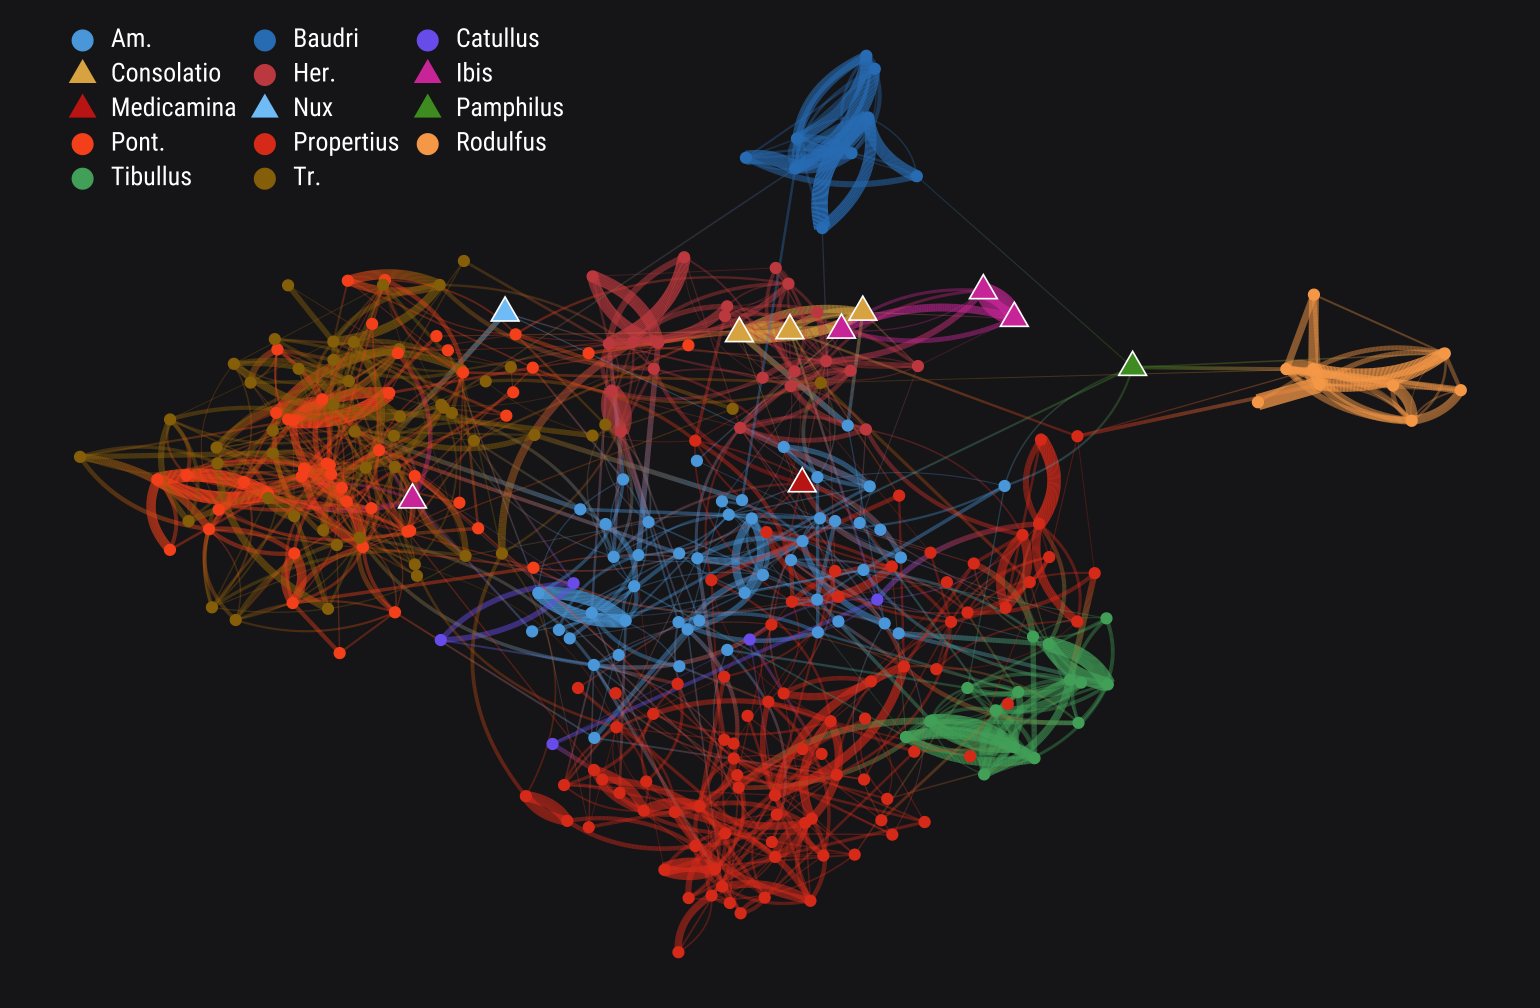

In [23]:
%%R -i graph_nini_small  -h 7 -w 10.7 -u in -r 144

# do_bct's default palette, but with Ibis moved off the yellow it shared with
# Consolatio, and Her., Pamphilus and Catullus lightened for the black
# background. Positional: the order is the sorted work names, ie legend order.
bct_palette <- c(
    "#58A8E0", # Am.
    "#3080C0", # Baudri
    "#7B68EE", # Catullus  (default #484880, 2.5:1 on black)
    "#E0B050", # Consolatio
    "#C94F4F", # Her.      (default #780000, 1.8:1 on black)
    "#D442A8", # Ibis      (default #F8E060, too close to Consolatio)
    "#C82818", # Medicamina
    "#80C8F8", # Nux
    "#4C9A2A", # Pamphilus (default #024f19, 2.1:1 on black)
    "#F85820", # Pont.
    "#E04020", # Propertius
    "#F8A858", # Rodulfus
    "#4eac6a", # Tibullus
    "#987008"  # Tr.
)

p <- do_bct(
    graph_nini_small,
    'white',
    '#1C1A1D',
    palette = bct_palette,
    lim=190,
    highlight=c("Nux", "Ibis", "Consolatio", "Medicamina", "Pamphilus"),
    legend_pos = c(0.2,0.9),
    flip=T
)
ggsave(
    plot=p,
    "../figures/bct_ngram_nini.pdf",
    dpi=600,
    width=10.7,
    height=7,
    device=cairo_pdf
)
ggsave(
    plot=p,
    "../figures/bct_ngram_nini.png",
    dpi=144,
    width=10.7,
    height=7,
    #device=cairo_pdf
)
p
